In [13]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting"
)

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import load_config

cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = (
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL"
)

print(cfg["data"])

from config import load_config

cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = (
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL"
)

print(cfg["data"])

from data import prepare

cache, manifest = prepare(cfg)

print("Cache:", cache)
print(manifest["splits"])

from pathlib import Path

FIG_DIR = Path("figures")

(FIG_DIR / "patchtst").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "tft").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "comparison").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "leads").mkdir(parents=True, exist_ok=True)


{'root': '/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL', 'sampling_rate': 100, 'history': 700, 'horizon': 300, 'synthetic': False, 'start': 0, 'layout': 'time_first'}
{'root': '/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL', 'sampling_rate': 100, 'history': 700, 'horizon': 300, 'synthetic': False, 'start': 0, 'layout': 'time_first'}
Cache: data/study_v3/ee7d4f585e459326
{'train': {'records': 339, 'patients': 300, 'windows': 339}, 'val': {'records': 81, 'patients': 75, 'windows': 81}}


In [ ]:
# Setup

In [5]:
import torch
import numpy as np
import pandas as pd

from models import build_model
from data import ECGDataset
from preprocessing import feature_arrays


LEAD_NAMES = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6"
]


def compute_lead_mae(
    architecture,
    preprocessing,
    checkpoint_path,
    cfg,
    cache,
):
    arrays, names, details = feature_arrays(
        cfg,
        cache,
        "F0",
        splits=("train", "val")
    )

    dataset = ECGDataset(
        cache,
        cfg,
        "val",
        preprocessing,
        arrays["val"]
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = build_model(
        architecture,
        static_dim=0,
        horizon=cfg["data"]["horizon"],
        **cfg["model"]
    )

    model.load_state_dict(checkpoint["model"])
    model.eval()

    lead_errors = []

    with torch.inference_mode():

        for idx in range(len(dataset)):

            sample = dataset[idx]

            history = sample["x"].unsqueeze(0)

            prediction = model(history).squeeze(0)

            target = sample["y"]

            mae_per_lead = (
                prediction - target
            ).abs().mean(dim=0)

            lead_errors.append(
                mae_per_lead.numpy()
            )

    lead_errors = np.asarray(lead_errors)

    mean_lead_mae = lead_errors.mean(axis=0)

    return pd.DataFrame({
        "Lead": LEAD_NAMES,
        "MAE": mean_lead_mae
    })

In [ ]:
# PatchTST P0

In [6]:
patchtst_p0_leads = compute_lead_mae(
    architecture="patchtst",
    preprocessing="P0",
    checkpoint_path=
    "results/primary_7s3s_v3/full/checkpoints/"
    "patchtst_P0_F0_full_120e/best.pt",
    cfg=cfg,
    cache=cache,
)

patchtst_p0_leads

,Lead,MAE
0,I,0.525251
1,II,0.607377
2,III,0.517576
3,aVR,0.570341
4,aVL,0.500289
5,aVF,0.570719
6,V1,0.503310
7,V2,0.505315
8,V3,0.544292
9,V4,0.575615


In [ ]:
# PatchTST P1

In [7]:
patchtst_p1_leads = compute_lead_mae(
    architecture="patchtst",
    preprocessing="P1",
    checkpoint_path=
    "results/primary_7s3s_v3/full/checkpoints/"
    "patchtst_P1_F0_full_120e/best.pt",
    cfg=cfg,
    cache=cache,
)

patchtst_p1_leads

,Lead,MAE
0,I,0.525251
1,II,0.607377
2,III,0.517576
3,aVR,0.570341
4,aVL,0.500289
5,aVF,0.570719
6,V1,0.503310
7,V2,0.505315
8,V3,0.544292
9,V4,0.575615


In [ ]:
# TFT P0

In [9]:
cfg["run_mode"] = "medium"
cache, manifest = prepare(cfg)

tft_p0_leads = compute_lead_mae(
    architecture="tft",
    preprocessing="P0",
    checkpoint_path=
    "results/primary_7s3s_v3/medium/checkpoints/"
    "tft_P0_F0_medium_60e/best.pt",
    cfg=cfg,
    cache=cache,
)

tft_p0_leads

,Lead,MAE
0,I,0.538428
1,II,0.554917
2,III,0.503056
3,aVR,0.561629
4,aVL,0.509237
5,aVF,0.521743
6,V1,0.456534
7,V2,0.480065
8,V3,0.518450
9,V4,0.531999


In [10]:
tft_p1_leads = compute_lead_mae(
    architecture="tft",
    preprocessing="P1",
    checkpoint_path=
    "results/primary_7s3s_v3/medium/checkpoints/"
    "tft_P1_F0_medium_60e/best.pt",
    cfg=cfg,
    cache=cache,
)

tft_p1_leads

,Lead,MAE
0,I,0.564816
1,II,0.598747
2,III,0.562347
3,aVR,0.592106
4,aVL,0.554934
5,aVF,0.576163
6,V1,0.488233
7,V2,0.480256
8,V3,0.524788
9,V4,0.540668


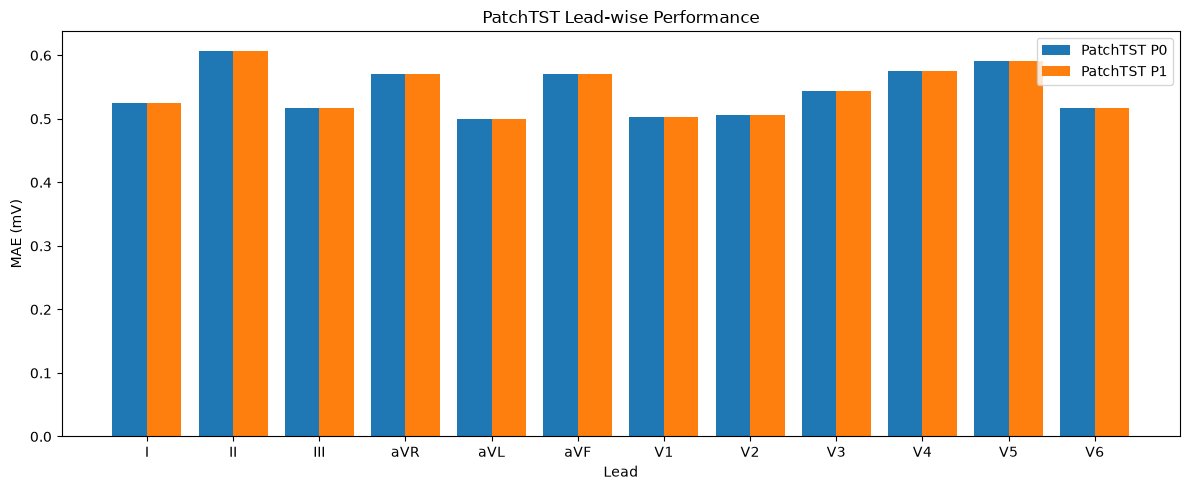

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12) - 0.2,
    patchtst_p0_leads["MAE"],
    width=0.4,
    label="PatchTST P0"
)

plt.bar(
    np.arange(12) + 0.2,
    patchtst_p1_leads["MAE"],
    width=0.4,
    label="PatchTST P1"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title("PatchTST Lead-wise Performance")

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tft" / "patchtst_p0_vs_p1_lead_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# TFT Leadwise Compariosn

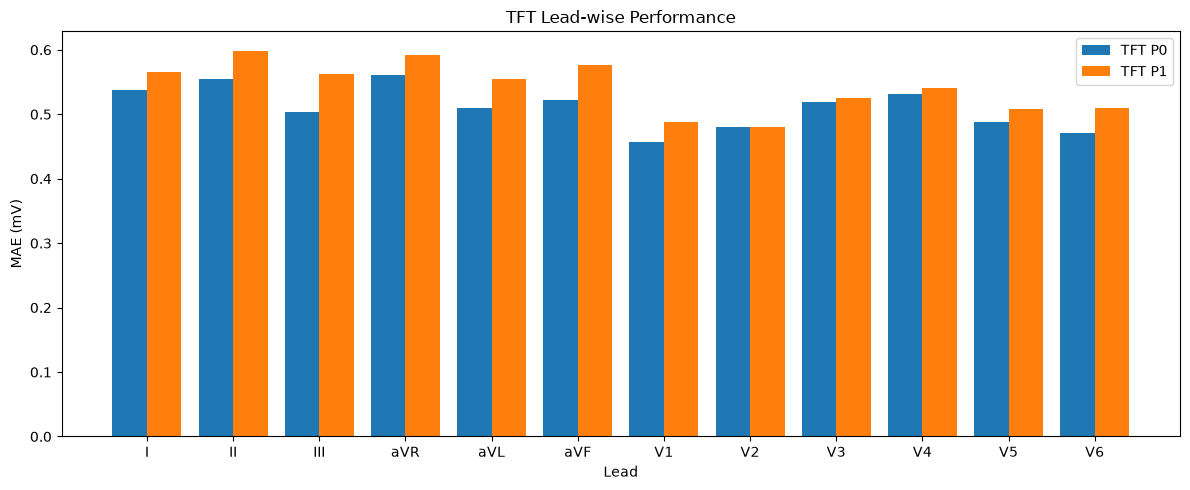

In [14]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12) - 0.2,
    tft_p0_leads["MAE"],
    width=0.4,
    label="TFT P0"
)

plt.bar(
    np.arange(12) + 0.2,
    tft_p1_leads["MAE"],
    width=0.4,
    label="TFT P1"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "TFT Lead-wise Performance"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tft" / "tft_p0_vs_p1_lead_mae.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 9.
Lead-wise MAE for TFT trained on raw (P0) and preprocessed (P1)
ECG signals. Differences between leads indicate how preprocessing
affects individual ECG channels.
"""

(
    FIG_DIR
    / "tft"
    / "tft_p0_vs_p1_lead_mae.txt"
).write_text(caption)

plt.show()

In [16]:
# PatchTST vs TFT Raw Data

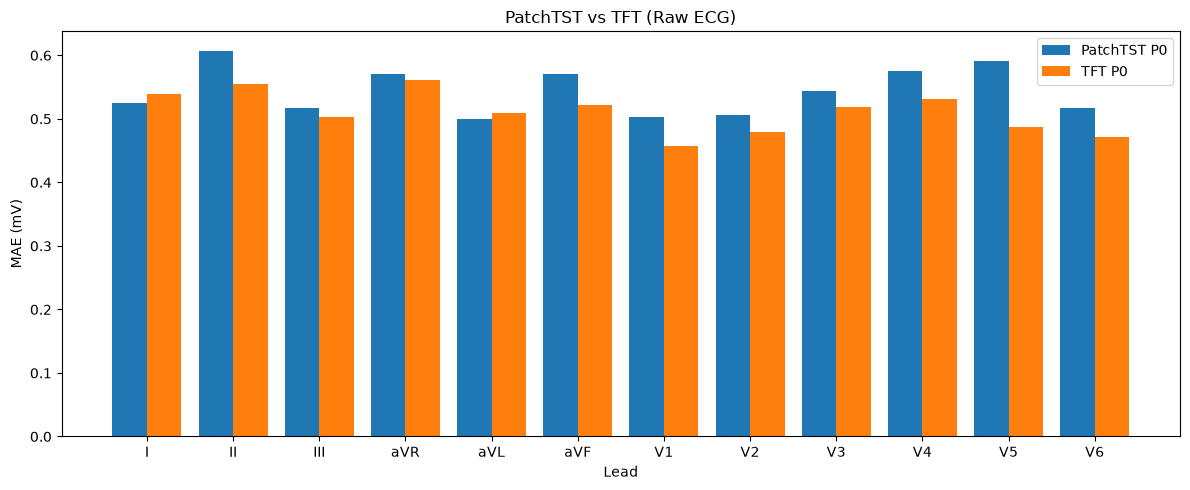

In [17]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12) - 0.2,
    patchtst_p0_leads["MAE"],
    width=0.4,
    label="PatchTST P0"
)

plt.bar(
    np.arange(12) + 0.2,
    tft_p0_leads["MAE"],
    width=0.4,
    label="TFT P0"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "PatchTST vs TFT (Raw ECG)"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR
    / "comparison"
    / "patchtst_vs_tft_p0_leads.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 10.
Lead-wise MAE comparison between PatchTST and TFT when trained
on raw ECG signals. Lower bars indicate better forecasting
performance for a specific ECG lead.
"""

(
    FIG_DIR
    / "comparison"
    / "patchtst_vs_tft_p0_leads.txt"
).write_text(caption)

plt.show()

# PatchTST vs TFT (Preprocessed)

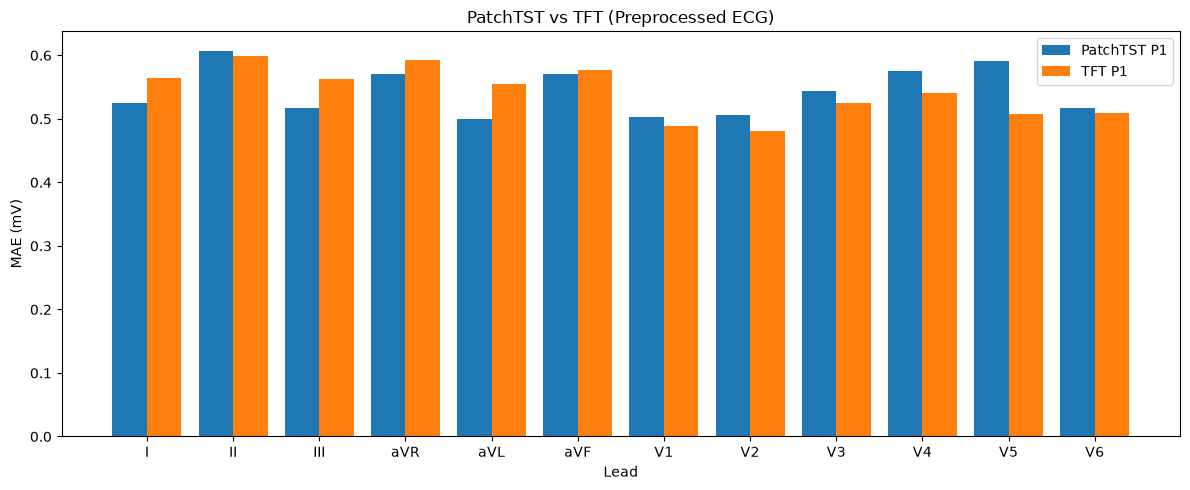

In [18]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    np.arange(12) - 0.2,
    patchtst_p1_leads["MAE"],
    width=0.4,
    label="PatchTST P1"
)

plt.bar(
    np.arange(12) + 0.2,
    tft_p1_leads["MAE"],
    width=0.4,
    label="TFT P1"
)

plt.xticks(
    np.arange(12),
    LEAD_NAMES
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "PatchTST vs TFT (Preprocessed ECG)"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR
    / "comparison"
    / "patchtst_vs_tft_p1_leads.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 11.
Lead-wise MAE comparison between PatchTST and TFT using
preprocessed ECG signals (P1).
"""

(
    FIG_DIR
    / "comparison"
    / "patchtst_vs_tft_p1_leads.txt"
).write_text(caption)

plt.show()

# Heatmap

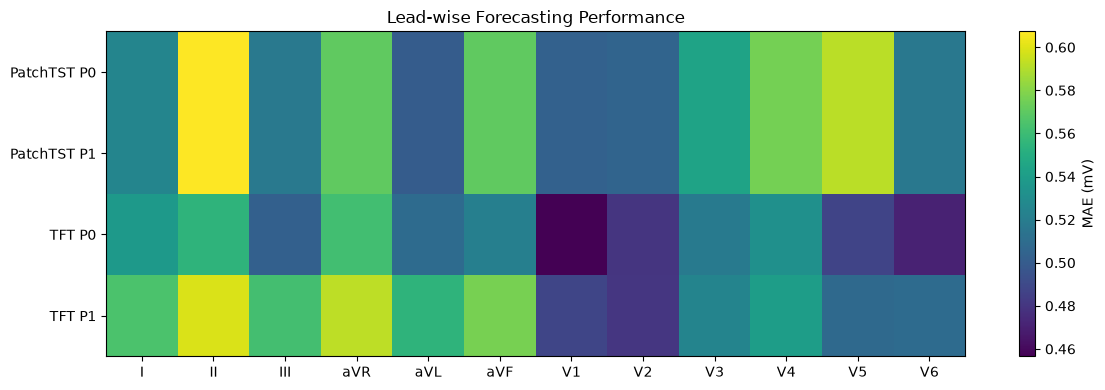

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

heatmap = pd.DataFrame(
    [
        patchtst_p0_leads["MAE"].values,
        patchtst_p1_leads["MAE"].values,
        tft_p0_leads["MAE"].values,
        tft_p1_leads["MAE"].values,
    ],
    index=[
        "PatchTST P0",
        "PatchTST P1",
        "TFT P0",
        "TFT P1",
    ],
    columns=LEAD_NAMES
)

plt.figure(figsize=(12,4))

plt.imshow(
    heatmap.values,
    aspect="auto",
)

plt.xticks(
    np.arange(len(LEAD_NAMES)),
    LEAD_NAMES
)

plt.yticks(
    np.arange(len(heatmap.index)),
    heatmap.index
)

plt.colorbar(
    label="MAE (mV)"
)

plt.title(
    "Lead-wise Forecasting Performance"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR
    / "comparison"
    / "lead_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 12.
Heatmap of lead-wise MAE for all transformer experiments.
Darker colors indicate lower forecasting error.
"""

(
    FIG_DIR
    / "comparison"
    / "lead_heatmap.txt"
).write_text(caption)

plt.show()